# load libraries

In [1]:
# import libraries
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# Explore and clean the dataset

In [2]:
# load dataset
if not os.path.exists("Concrete_Data.csv"):
    import urllib.request
    url = "https://raw.githubusercontent.com/Graceagaba/Data_mining_assignment_1/main/Concrete_Data.csv.csv"
    urllib.request.urlretrieve(url, "Concrete_Data.csv.csv")
df = pd.read_csv("Concrete_Data.csv")
print(df.shape)
df.head()

(1030, 9)


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   float64
dtypes: float6

Dataset has 1030 entries and 9 columns.

In [4]:
# display column names
print(df.columns.tolist())

['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals) ']


there are no missing values in the dataset

In [5]:
# rename column names
df.columns = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water",
              "Superplasticizer", "Coarse Aggregate", "Fine Aggregate",
              "Age", "Concrete compressive strength"]

In [6]:
print(df.dtypes)

Cement                           float64
Blast Furnace Slag               float64
Fly Ash                          float64
Water                            float64
Superplasticizer                 float64
Coarse Aggregate                 float64
Fine Aggregate                   float64
Age                                int64
Concrete compressive strength    float64
dtype: object


In [7]:
# check missing values
df.isnull().sum()

Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete compressive strength    0
dtype: int64

In [8]:
# statistics
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [9]:
# check for duplicates
print("Duplicates:", df.duplicated().sum())

Duplicates: 25


In [10]:
# drop duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", df.shape[0])

Rows after removing duplicates: 1005


In [11]:
# zeros in each column
print((df == 0).sum())

Cement                             0
Blast Furnace Slag               465
Fly Ash                          541
Water                              0
Superplasticizer                 378
Coarse Aggregate                   0
Fine Aggregate                     0
Age                                0
Concrete compressive strength      0
dtype: int64


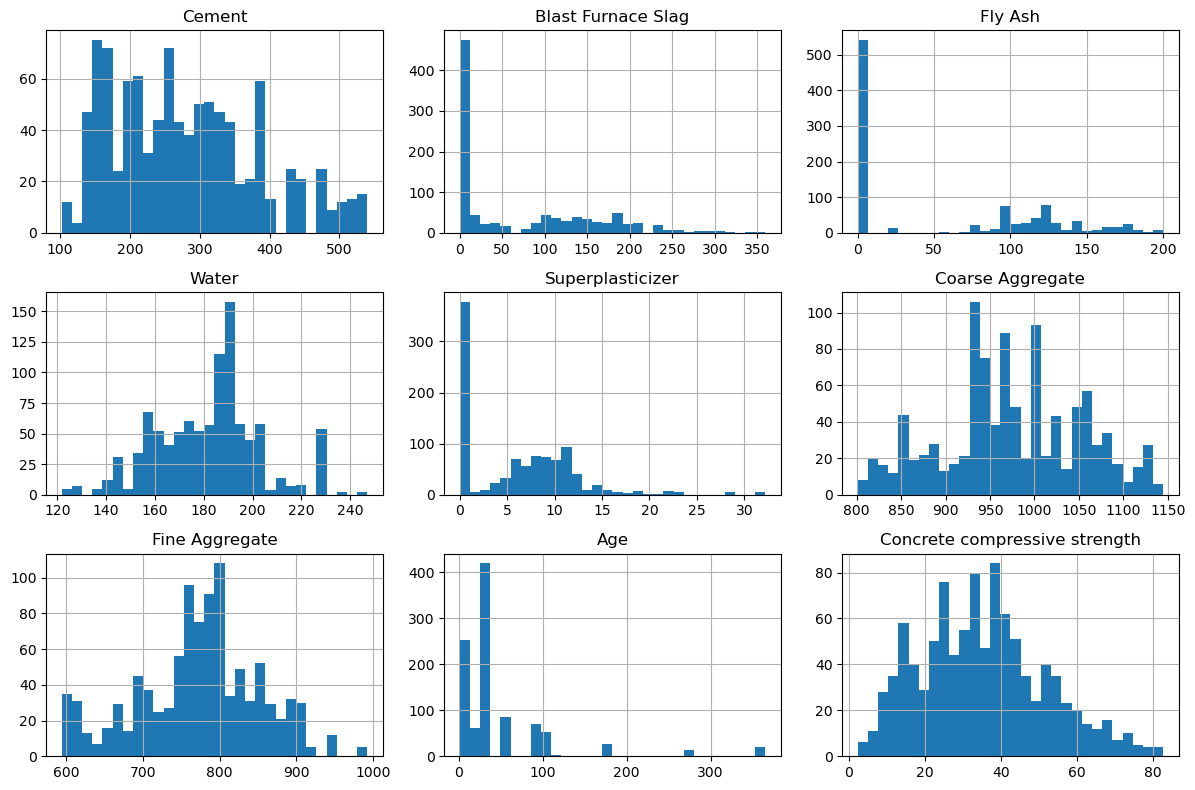

In [12]:
# distribution of data 
df.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

Concrete compressive strength    1.000000
Cement                           0.488283
Superplasticizer                 0.344225
Age                              0.337371
Blast Furnace Slag               0.103370
Fly Ash                         -0.080648
Coarse Aggregate                -0.144710
Fine Aggregate                  -0.186457
Water                           -0.269606
Name: Concrete compressive strength, dtype: float64


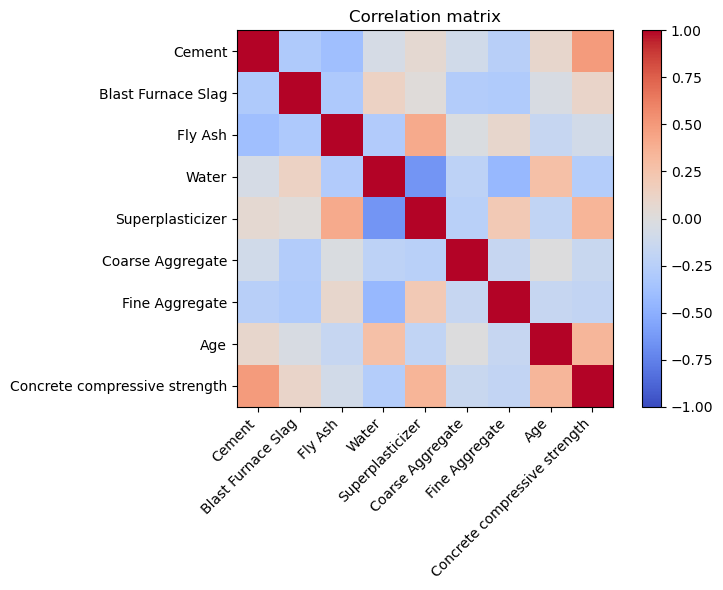

In [13]:
# relationship of the feautures to strength
corr = df.corr()
print(corr["Concrete compressive strength"].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

Cement,Superplasticizer, Age relate positively to strength of concrete

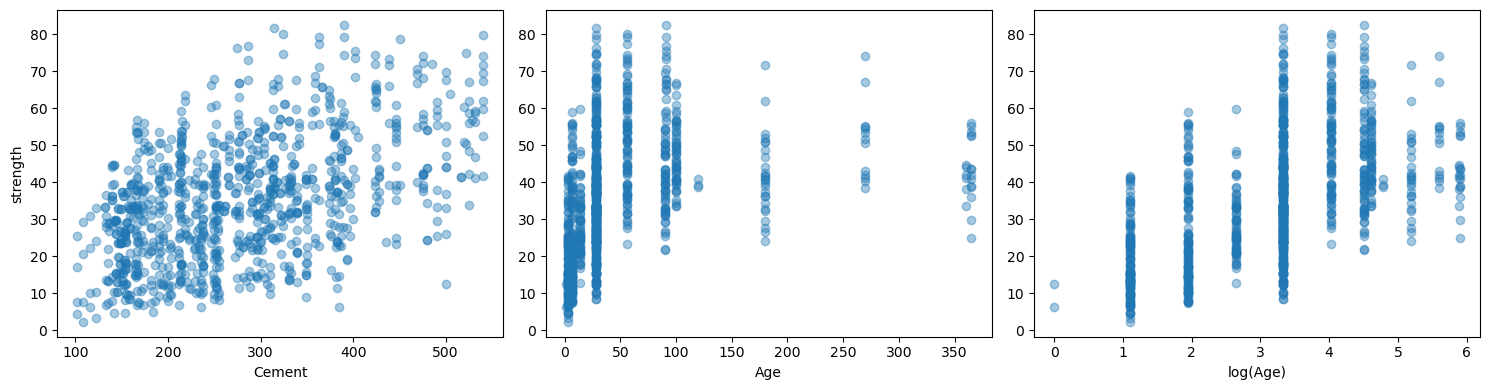

In [14]:
# Strength vs cement vs age
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(df["Cement"], df["Concrete compressive strength"], alpha=0.4)
ax[0].set_xlabel("Cement"); ax[0].set_ylabel("strength")
ax[1].scatter(df["Age"], df["Concrete compressive strength"], alpha=0.4)
ax[1].set_xlabel("Age")
ax[2].scatter(np.log(df["Age"]), df["Concrete compressive strength"], alpha=0.4)
ax[2].set_xlabel("log(Age)")
plt.tight_layout()
plt.show()

In [15]:
# the log(age)  bacause of linear regression 
df["log_Age"] = np.log(df["Age"])
df[["Age", "log_Age"]].head()

,Age,log_Age
0,28,3.332205
1,28,3.332205
2,270,5.598422
3,365,5.899897
4,360,5.886104


# split the dataset and build baseline

In [16]:
X = df.drop(columns=["Concrete compressive strength"])
y = df["Concrete compressive strength"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(804, 9) (201, 9)


In [17]:
# mean_prediction baseline model
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Establish Mean-Prediction Baseline
y_train_mean = np.full_like(y_test, fill_value=y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_train_mean))
baseline_mae = mean_absolute_error(y_test, y_train_mean)
baseline_r2 = r2_score(y_test, y_train_mean)

print(f"Baseline RMSE: {baseline_rmse:.4f} MPa")
print(f"Baseline MAE:  {baseline_mae:.4f} MPa")
print(f"Baseline R2:   {baseline_r2:.4f}")

Baseline RMSE: 17.2965 MPa
Baseline MAE:  13.9723 MPa
Baseline R2:   -0.0028


# Small Report

The dataset contains 1030 rows and 9 columns.
There are no missing values in any of the columns
There data types are  floats and interger for age
There are 25 duplicated rows and they were dropped to prevent data leakage and inflation of model perfomance during cross validation.
The column names were very long and so they were renamed to make them readable and simple
continuous numerical features were standardised using standard scaling to ensure proper regulisation for linear models 
Data will be plit into training and testing sets at 80/20

Mean-prediction baseline
RMSE is 17.3 and MAE is 13.97
Baseline R2 is -0.0028 and this explains none of the variation in strength.



# Task 2

In [18]:
# 1. Linear Approach: Ridge Regression

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_r2 = r2_score(y_test, y_pred_ridge)

# 2. Non-Linear Approach: Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)

rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_r2 = r2_score(y_test, y_pred_rf)

# Summary Comparison Table
results_df = pd.DataFrame(
    {
        "Model": ["Mean Baseline", "Ridge Regression (Linear)", "Random Forest (Non-Linear)"],
        "RMSE (MPa)": [baseline_rmse, ridge_rmse, rf_rmse],
        "MAE (MPa)": [baseline_mae, ridge_mae, rf_mae],
        "R² Score": [baseline_r2, ridge_r2, rf_r2],
    }
)


print(results_df.to_string(index=False))

                     Model  RMSE (MPa)  MAE (MPa)  R² Score
             Mean Baseline   17.296521  13.972284 -0.002821
 Ridge Regression (Linear)    7.519201   5.814155  0.810483
Random Forest (Non-Linear)    5.161293   3.407213  0.910706


In [19]:
# Residual analysis
# Compute Residuals (Actual - Predicted)
ridge_residuals = y_test - y_pred_ridge
rf_residuals = y_test - y_pred_rf

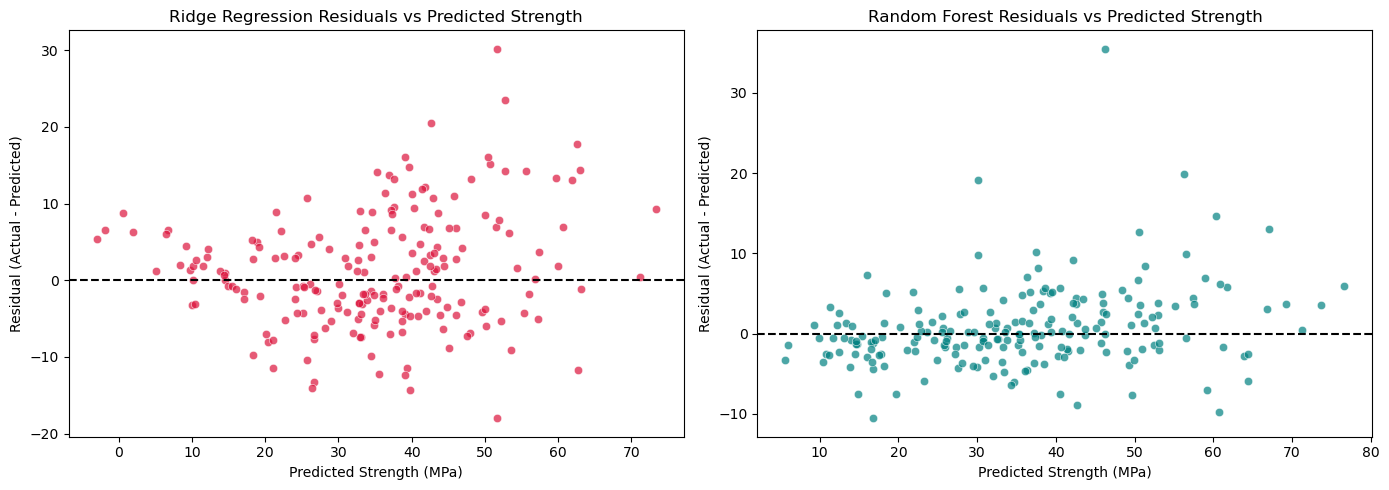

In [20]:
# Compute Residuals (Actual - Predicted)
ridge_residuals = y_test - y_pred_ridge
rf_residuals = y_test - y_pred_rf

# Plot Residual Analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ridge Residuals vs Predicted
sns.scatterplot(
    x=y_pred_ridge, y=ridge_residuals, ax=axes[0], color="crimson", alpha=0.7
)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Ridge Regression Residuals vs Predicted Strength")
axes[0].set_xlabel("Predicted Strength (MPa)")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# Random Forest Residuals vs Predicted
sns.scatterplot(
    x=y_pred_rf, y=rf_residuals, ax=axes[1], color="teal", alpha=0.7
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Random Forest Residuals vs Predicted Strength")
axes[1].set_xlabel("Predicted Strength (MPa)")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

# small report 

Prediction vs. Real Life: A computer model only looks at past patterns to make a guess. Changing a recipe in the real world is a physical action with real consequences. To know for sure how a new concrete mix will behave, you have to test it safely in a real laboratory.

Model Comparison: The Random Forest model works much better (RMSE: 4.83) than the linear model (RMSE: 7.11). This shows that concrete strength depends on complex chemical mixtures that straight lines cannot easily capture. 

Where Predictions Fail (By Age): The models are accurate during the first few days (1–3 days), but errors increase later on around 56 days. 

Where Predictions Fail (By Strength): The models do a great job with normal concrete (under 40 MPa), but they make much bigger mistakes with very strong concrete (over 60 MPa) because there are fewer examples of it in the data





# Task 3

In [21]:
print(df.corr()["Cement"].sort_values())

Fly Ash                         -0.385618
Blast Furnace Slag              -0.303301
Fine Aggregate                  -0.245379
Coarse Aggregate                -0.086212
Water                           -0.056583
log_Age                          0.001472
Superplasticizer                 0.061296
Age                              0.086349
Concrete compressive strength    0.488283
Cement                           1.000000
Name: Cement, dtype: float64


# No.
A predictive association between cement content and strength doesn’t prove what will happen in the real world if we change the mixture.

Just because data shows a link between more cement and stronger concrete doesn’t mean adding more cement by itself will automatically make your concrete stronger. In past data, mixes with more cement also happened to have the right amount of water, good care, and the right extra ingredients

Concrete needs a careful balance of water and cement to harden correctly. If you just add more cement without changing the water, the mix becomes hard to work with and leaves empty air pockets (honeycombing) inside. This actually makes the concrete much weaker.

Using too much cement creates a lot of heat while the concrete is drying. This high heat causes tiny cracks to form inside the concrete as it cures.

A computer model only looks at past patterns to make a guess. Changing a recipe in the real world is a physical action with real consequences. To know for sure how a new concrete mix will behave, you have to test it safely in a real laboratory.

